# Relative presence share by facility (RQ1)
Yogyakarta · JogjaPulse · Role 4

Open this notebook in Google Colab and choose **Runtime → Run all**. The notebook includes the upstream summary tables needed for this figure. The final cell displays the result and writes a PNG to the current directory.

In [1]:
from pathlib import Path
from io import BytesIO
import base64, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Image

PRIMARY_PERIODS = ['2021_Dec', '2022_Jan', '2022_Feb_P1', '2022_Feb_P2']
COLORS = {
    "education_campus": "#0072B2",
    "healthcare_hospital": "#CC6677",
    "commercial_mall": "#AA4499",
    "traditional_market": "#B57700",
    "tourism_site": "#00896B",
    "transit_hub": "#674EA7",
    "baseline_candidate": "#647482",
    "mixed_use": "#503E35",
    "no_selected_facility": "#CBD2D4",
}
LABELS = {
    "education_campus": "Campuses",
    "healthcare_hospital": "Hospitals",
    "commercial_mall": "Malls",
    "traditional_market": "Markets",
    "tourism_site": "Tourism",
    "transit_hub": "Transit",
    "baseline_candidate": "Baseline candidates",
    "mixed_use": "Mixed use",
    "no_selected_facility": "No selected facility mapped",
}
MISSING = "#d9dfe2"
BREAK = pd.Timestamp("2022-01-01")

PERIOD_NAMES = {
    "2021_Dec": "December 2021",
    "2022_Jan": "January 2022",
    "2022_Feb_P1": "February 1–15",
    "2022_Feb_P2": "February 16–28",
    "2022_Mar_Apr_Exploratory": "March–April (exploratory)",
}


## Source data
Snapshot of `data/gold/facility_pull.parquet` generated by the merged project pipeline. Expand the folded cell to inspect the embedded data.

In [2]:
# @title Load the embedded summary tables
encoded = {'gold/facility_pull': 'eNqNl92OGrsShe/Ps7SQq+zyz/3WuThX5w0QgVYGhYERMIn22++vbDIDe4ig6e5JGtNeXrVqVfm0en3bbfffl2/zcXvYTOPP8sd2v5nWq/P8/XD8e1rPu91pWu/eT+f5+PmP5a/t+WX5c7V7n6fXebNd7Zenl9VxXv6a5x+b1d/Lt/V5Wm+Xu8Mv//Oy/f7yddy83/Rxly9eZ278WW03p9/v+f3dBdv68HM+rr7P0/xzu5n36/k/GlSWf83r6e24fV054MPr63xcb1c73rTbTaKXMywkqNVoTWvS0koqPAtacqohRbVooVk1H1iL1lpCSxZC1Zx9YMk1ZpXKkUKZqiwklWC1ajRtiTkWYTrOb4fjed58xTVv3iF1e9gv1/D+fpqKThb95N05lxJzrDVLKbUkf5ZaCqmoxBhBnLWDqCYlhMxCpEUA+jOTJKVqi800aTDeeQtNHkA7H1ebrUPrnB1/zOfJ6mTFTwdnpVWoSdVai6pjTgkRzuDRsvoaRKSFmCCwQWWMtQ+znBiZcsiaiji2vOiQBNo7xPQY3P60PS9f3r9N4ixr7Ze/HbZyq1ZqDJH1d4Z4q2YiyWxB+MGIXcpAh13TkFLsnPNV5dMCY2G3TckWn5Q5PnsA7dvqNJNAMxHdb7YbUmZKKXxcjjAxS+R1CEqSXQASRGkiNTFbD3UOFhsRTGC0bDYY9lg3iyEztNQplcUVthLyI+IO78ft6XUJefNUdSrRzy4sGGomuSWI6iFGeU1q0IgOnaoOiszILcdCAEsunXESwJw4ggkGBDfFvLhWmpRH8XyZV7vzy9o94OVwetueV7uJsMbmp6PLWUm8EEsUbZ2K2AoTqiOOiFD8WSsthhKjuDCt9Gfki6GxXEnbatVfehvRrwHV5X/nb8v/yx/tQ8PlROGImmkRmxZrRK8nJNFBWqa4CHP4EshMDCJUEUZq62sQ5bBWyJCYmks4yaIU/fzUx9i+WAiR8cjWnpKsk+TMRYqBJAwRZUgiSZXogm6YIH4BasdRxcYqckmxNMUF4bIyrhbAPAR0nZuaoYlA+uUZ13gRhkkYkUe24XKInLAagUplyLyhrRANjPxEpccx14DiQyg1My7EqSYf+PGRJ5Bdi19QlpBpMrLNoBtGUAh5F9rICSKKnyY8PsWRpxkDhjlxVBolX5KysiCfsSG3PGV5hqd7mmcVtfrprw05RsJmxRCHhDxUT/IbeRaR8qVYQScmoQVQZKTa8LGUFX+BafIhpclu2aJIPBPIf1cAUWhG99K1HxLqb+5SJbWCB3SEXgwLoTKzmHMdQca0JFDJ0BxuNqIMMjOMzzPWq8aU4oK0/fw8kZl33FaE8slNx82rubbOBJE1qsSIZA9gxK9U0H7q2CGNjGFxEMTAXsIYiCTU34qrZH6sz1Kpf+4/yuUMC0TkLYU0XNflPlqNRvZ5EQooMjdfhdOGWQCMPKk9n6izbm4Qn5NaLigvLvLNkR5j+9qD5I8yT0XCERoICjzVXiqE+i2Z/6rDzv5IvVdBjsk9hVLfLSXVpl5wodml2ouCXh+Pod3rQegWXM2dJRyqSkV/CEt6MoAnUeEDUC3TYOROE/XdDRCtkt49QfB9ZEcX59KlSYpeFtLN8Rje3aolH1ULzVMQiCOpQJnpTQcO34u5Ks0A0fR1aAoVY4QcXMxdqP9WrXgLgCQSumydvuujPkXfZ5fkNdhav8byvVjSG3Lm0imhEjFhVoKFcnptl0ZNZwFkM4sJtcfffwptCcvmMQGJtog3R34C27UXs+TcT0dBx0EvAhuWcLQ+Y/I+yTUX4ZRkHMiYnqThmVepsQLSgJjTzrv2YpmiLuoNssfA7jiKhvpxeU+LxivZWJQyH7sSYQa3ZcOAmxHhNhoD0o9oVydqVFmJmb6AVA2+v0CcCr7r456V/G+1/7OP2OV0DClQMylnFQ+DsLE9Qfd4HP7goeymEdFOpKLh5YlxlyV5UyneYJn3cTSFd0vYNZavvvGZmhRQggMc6jWFVkYvUggoVanSw1HILx0QJZamCN1RQIfmAr7HGHdcOvkyZfdbw0XGXR7gulG9eVOV+jVQmceDVRb6xzI2T16PcFB6akxXOgJ2N9CDwBIW3CsvqHwHAWU0fM6ney32C8OX+xO47m2o+unYtDIHLZevv3c8TIMLVLrtGmjNx34qixOYixNGkg60yu6BXUuk36STIpGeqALX0O4aGZsL83MgoQoFkJBfl6KaaUB8A2csX33H5ujcT9gNtkRTHC69MDFEAjh1RmGUMjZ7n6T5/RFvN1sW9isyjc6etgGDZcPSNy2jE6oJjZBmMVJ3ykV1FcXzViHnBtf0S+IdBthoTbJMCfO/AfWIsbu7PPm4evdMF2Tuqc056Vh8Z0s1oBVC8GXshmnlqrs8VTz87vKIbmEYbwI8P01pccPYv0rnP2Zkeps='}
tables = {k: pd.read_csv(BytesIO(zlib.decompress(base64.b64decode(v)))) for k, v in encoded.items()}
def read(layer, name, columns):
    frame = tables[f'{layer}/{name}'].copy()
    missing = set(columns.split()) - set(frame)
    if missing:
        raise ValueError(f'{name} is missing {sorted(missing)}')
    return frame
def gold(name, columns):
    return read('gold', name, columns)
for key, frame in tables.items():
    print(key, frame.shape)
    display(frame.head(3))


gold/facility_pull (28, 13)


,sampling_period,period_kind,category,cells,clusters,clusters_with_value,median_share_weekday_pct,ci_low,ci_high,median_share_weekend_pct,median_mean_n_maids_weekday,median_period_coverage,evidence
0,2021_Dec,primary,commercial_mall,12,12,12,0.102584,0.027648,0.187289,0.076836,81.147059,1.0,reported
1,2021_Dec,primary,education_campus,72,53,53,0.066774,0.049405,0.085170,0.051418,53.147059,1.0,reported
2,2021_Dec,primary,traditional_market,58,57,57,0.065798,0.051103,0.111903,0.055641,56.529412,1.0,reported


## Build the figure
Each category is summarized within a sampling period over cells clearing the 90% weekday and weekend coverage rule. Bars show median ordinary-weekday restricted presence share (%), lines show 95% site-cluster bootstrap confidence intervals, and white circles show median weekend presence share.

In [3]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlecolor': '#224853'})

def heading(fig, title, description):
    fig.suptitle(
        title + "\n" + description,
        x=0.025,
        ha="left",
        fontsize=15.5,
        color="#163c45",
    )


def save(fig, path):
    fig.savefig(path, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def pull(path):
    """Render RQ1 Facility Pull: median weekday/weekend presence share (%) with site-cluster CIs."""
    table = gold(
        "facility_pull",
        "sampling_period category cells clusters median_share_weekday_pct ci_low ci_high median_share_weekend_pct evidence",
    )
    periods = [p for p in PRIMARY_PERIODS if p in set(table.sampling_period)]
    if not periods:
        periods = sorted(set(table.sampling_period))
    cats = [c for c in LABELS if c in set(table.category)]
    fig, axes = plt.subplots(
        (len(periods) + 1) // 2,
        2,
        figsize=(16, 3.9 * ((len(periods) + 1) // 2)),
        layout="constrained",
        squeeze=False,
    )
    for ax, period in zip(axes.flat, periods):
        rows = (
            table[table.sampling_period.eq(period)].set_index("category").reindex(cats)
        )
        base_val = (
            rows.at["baseline_candidate", "median_share_weekday_pct"]
            if "baseline_candidate" in rows.index
            and rows.at["baseline_candidate", "evidence"] == "reported"
            else np.nan
        )
        if pd.notna(base_val):
            ax.axvline(base_val, color="#647482", ls="--", lw=1.1, zorder=1)
        for i, (cat, row) in enumerate(rows.iterrows()):
            if row.evidence == "reported":
                ax.barh(
                    i,
                    row.median_share_weekday_pct,
                    color=COLORS[cat],
                    height=0.48,
                    alpha=0.92,
                )
                ax.plot([row.ci_low, row.ci_high], [i, i], color="#14242b", lw=2.5)
                if pd.notna(row.median_share_weekend_pct):
                    ax.scatter(
                        row.median_share_weekend_pct,
                        i,
                        marker="o",
                        s=30,
                        color="white",
                        edgecolor="#182933",
                        zorder=4,
                    )
            counts = (
                "no eligible cells"
                if pd.isna(row.cells)
                else f"{int(row.cells):,} / {int(row.clusters):,}"
            )
            ax.text(
                1.02,
                i,
                ("withheld   " if str(row.evidence).startswith("withheld") else "")
                + counts,
                transform=ax.get_yaxis_transform(),
                va="center",
                fontsize=8,
            )
        ax.set_yticks(range(len(cats)), [LABELS[c] for c in cats])
        for tick_label, cat_key in zip(ax.get_yticklabels(), cats):
            if cat_key == "education_campus":
                tick_label.set_fontweight("bold")
                tick_label.set_color("#005689")
        ax.invert_yaxis()
        ax.set_title(
            PERIOD_NAMES.get(period, period), loc="left", fontweight="bold", pad=18
        )
        ax.text(1.02, 1.02, "Cells / clusters", transform=ax.transAxes, fontsize=8)
        ax.grid(axis="x", alpha=0.14)
        ax.set_axisbelow(True)
        ax.set_xlabel("Median restricted presence share (%)")
    for ax in list(axes.flat)[len(periods) :]:
        ax.set_visible(False)
    legend_handles = [
        Patch(facecolor="#0072B2", label="Weekday median share (≥90% coverage)"),
        Line2D([0], [0], color="#14242b", lw=2.5, label="95% site-cluster bootstrap CI"),
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor="white",
            markeredgecolor="#182933",
            markersize=6,
            label="Weekend median share",
        ),
        Line2D(
            [0],
            [0],
            color="#647482",
            ls="--",
            lw=1.1,
            label="Baseline candidate weekday median",
        ),
    ]
    fig.legend(
        handles=legend_handles,
        loc="outside lower center",
        frameon=True,
        facecolor="white",
        edgecolor="#d9dfe2",
        fontsize=9.5,
        ncol=4,
    )
    reported = table[
        table.sampling_period.isin(periods)
        & (table.evidence == "reported")
        & (table.category != "baseline_candidate")
    ]
    top_count = 0
    if not reported.empty:
        leaders = reported.loc[
            reported.groupby("sampling_period")["median_share_weekday_pct"].idxmax()
        ]
        top_count = (leaders.category == "commercial_mall").sum()
    result = (
        f"Mall and campus cells drew higher relative weekday presence than baseline candidates across all {len(periods)} primary periods "
        f"(malls led in {top_count} of {len(periods)} periods)."
        if len(periods)
        else "The data did not support a facility pull comparison."
    )
    heading(
        fig,
        "Relative device presence share by facility category (RQ1)",
        "What we built: Bars show median weekday presence share (%) among eligible cells within each period.\n"
        "Lines show 95% site-cluster bootstrap intervals. White circles show median weekend share.\n"
        f"What we found: {result}",
    )
    save(fig, path)


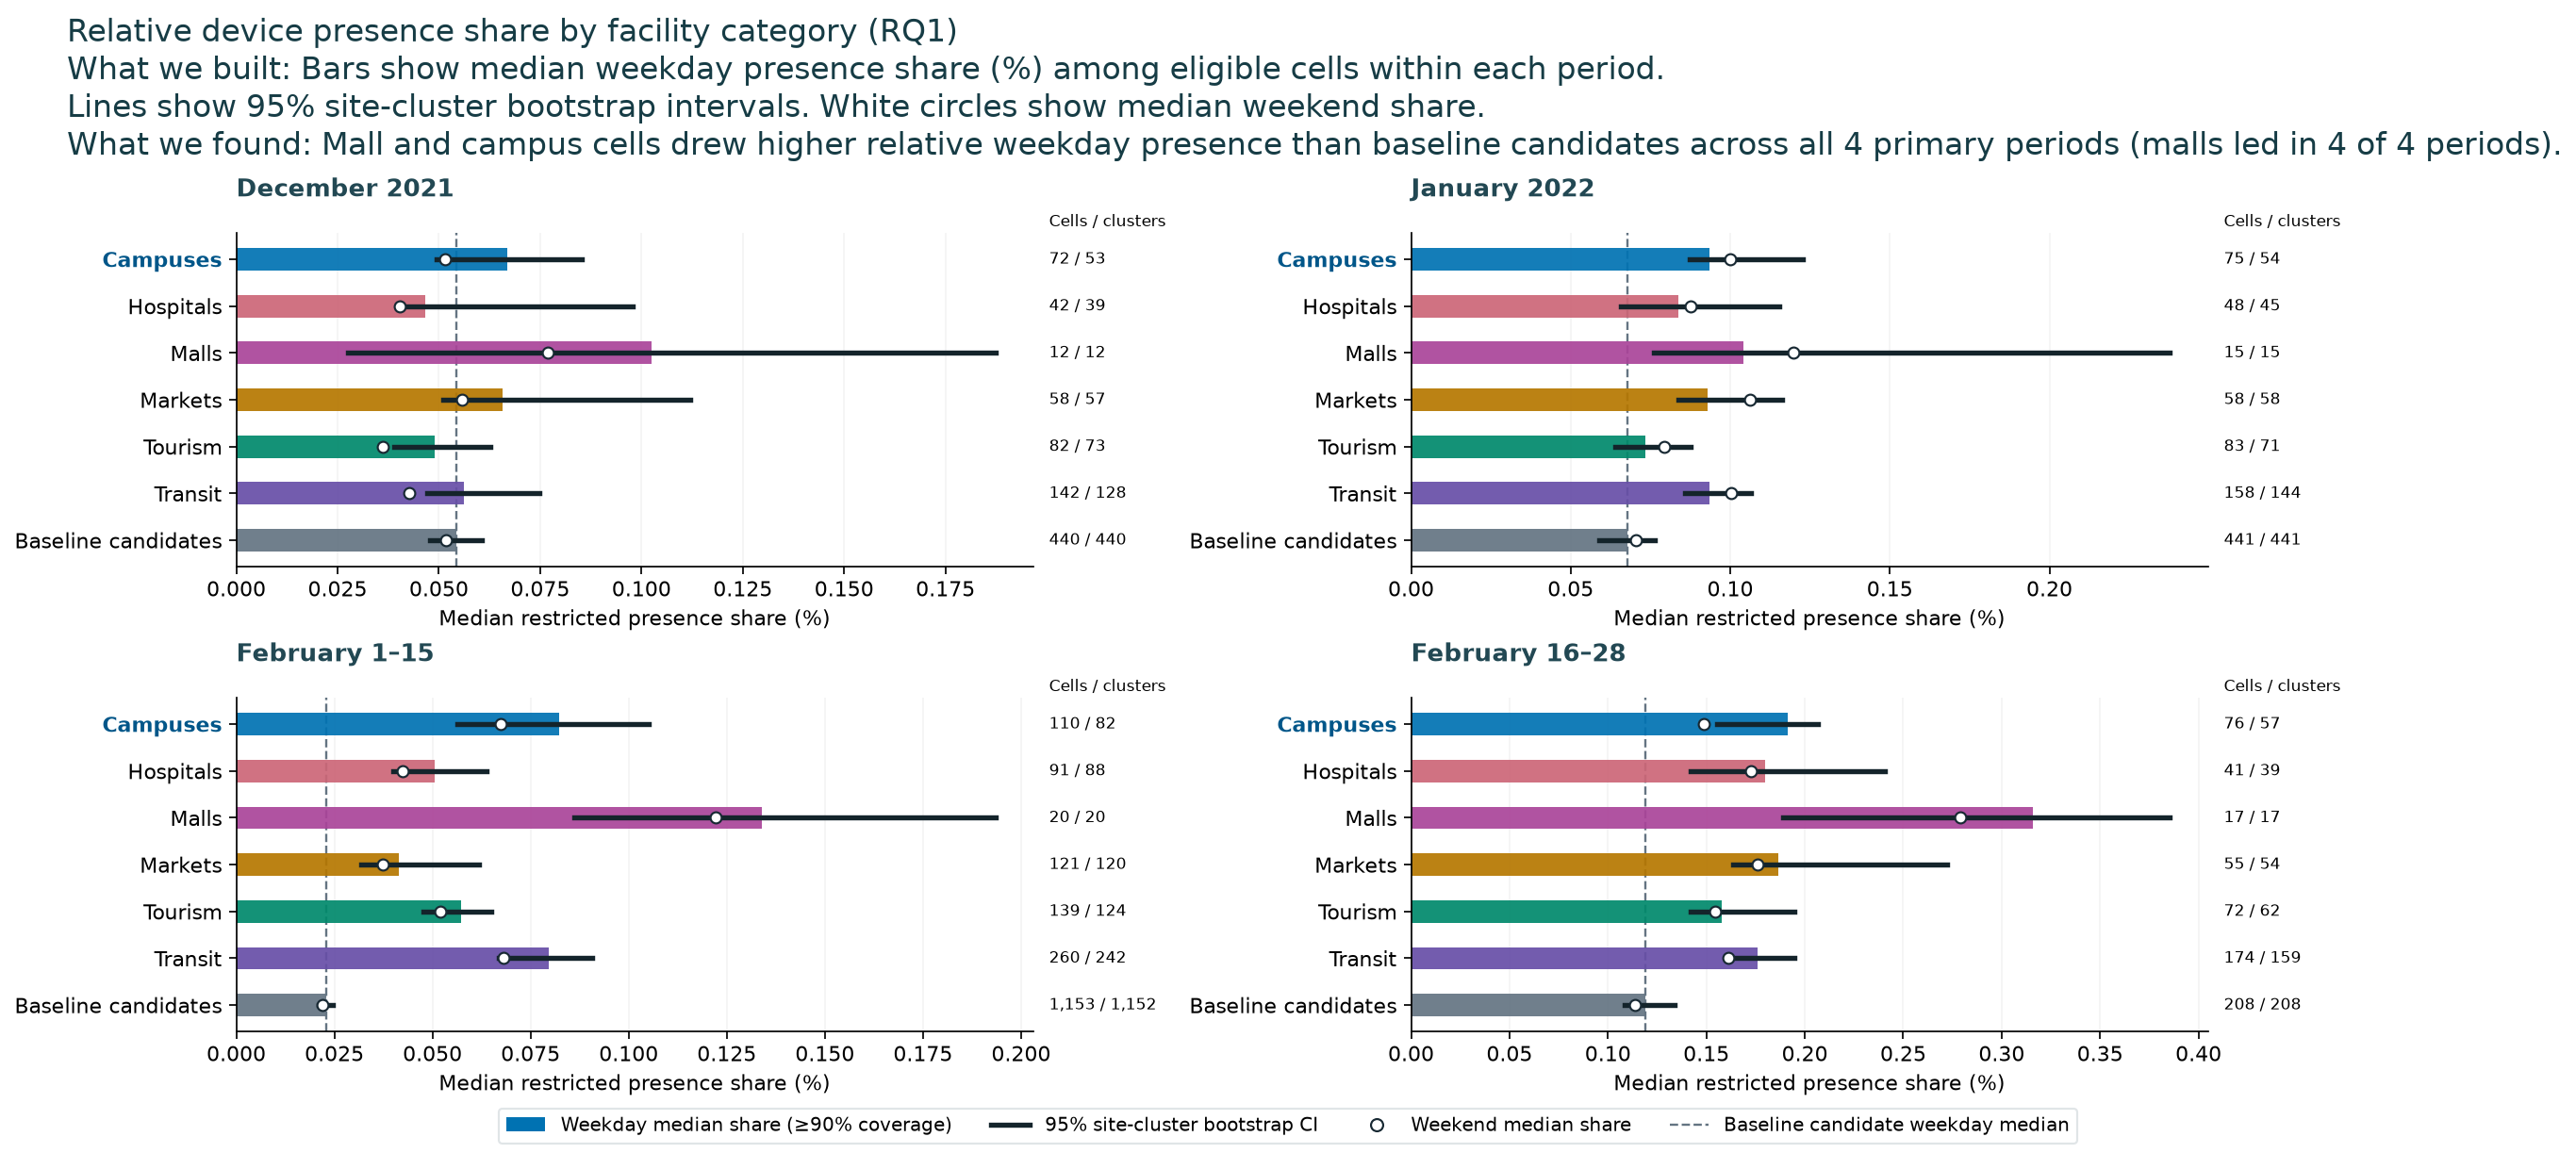

In [4]:
output = Path('facility_pull.png')
pull(output)
display(Image(filename=str(output)))